# Do Fraud Flags Detect Counterfeits?
A feature-importance study on synthetic e-commerce transactions.

Run the cells top to bottom. Cell 2 asks you to upload `_counterfeit_transactions.csv`.

In [1]:
# 1. Imports and pipeline code (nothing to edit)
"""
Do Fraud Flags Detect Counterfeits?
A feature-importance study on synthetic e-commerce transactions.

Usage:  python3 counterfeit_pipeline.py <data.csv> <output_dir>

Stages
  1. Load, clean, encode
  2. Descriptive checks and rule baselines
  3. Feature-group ablation (repeated stratified 5-fold CV, paired folds)
  4. Temporal hold-out and group permutation importance
  5. Hard mode: do the flags add anything once the dominant features are removed?
  6. Robustness: lower prevalence and label noise
  7. Figures

Only pandas / numpy / scipy / scikit-learn / matplotlib are required.
"""
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, f1_score, matthews_corrcoef,
                             precision_recall_curve, roc_auc_score)
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
SEED = 42
TARGET = "involves_counterfeit"
CATEGORICAL = ["customer_location", "payment_method", "shipping_speed"]

GROUPS = {
    "A_behavioral_flags": ["velocity_flag", "geolocation_mismatch", "device_fingerprint_new"],
    "B_order_composition": ["quantity", "unit_price", "total_amount",
                            "discount_applied", "discount_percentage"],
    "C_payment_fulfilment": ["payment_method", "shipping_speed", "shipping_cost"],
    "D_customer_context": ["customer_history_orders", "customer_age", "customer_location"],
    "E_post_transaction": ["refund_requested", "delivery_time_days"],  # leakage-prone
}
DOMINANT = ["quantity", "unit_price", "total_amount", "customer_history_orders",
            "payment_method", "shipping_speed"]

MODELS = {
    "LogReg": lambda: make_pipeline(StandardScaler(),
                                    LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Tree(d=4)": lambda: DecisionTreeClassifier(max_depth=4, class_weight="balanced",
                                                random_state=SEED),
    "RandForest": lambda: RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                                                 n_jobs=-1, random_state=SEED),
    "HistGB": lambda: HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
}


# ------------------------------------------------------------------ 1. data
def load(path):
    df = pd.read_csv(path)
    df["transaction_date"] = pd.to_datetime(df["transaction_date"], format="mixed")
    df = df.sort_values("transaction_date").reset_index(drop=True)
    y = df[TARGET].astype(int).values
    X = df.drop(columns=[TARGET, "transaction_id", "customer_id", "transaction_date"])
    for c in X.select_dtypes("bool").columns:
        X[c] = X[c].astype(int)
    X = pd.get_dummies(X, columns=CATEGORICAL, dtype=int)
    return df, X, y


def cols(X, names):
    out = []
    for n in names:
        out += [c for c in X.columns if c == n or c.startswith(n + "_")]
    return out


def metrics(y, p):
    prec, rec, _ = precision_recall_curve(y, p)
    ok = prec >= 0.95
    return {
        "PR_AUC": average_precision_score(y, p),
        "ROC_AUC": roc_auc_score(y, p),
        "F1": f1_score(y, p >= 0.5),
        "MCC": matthews_corrcoef(y, p >= 0.5),
        "Recall@P95": rec[ok].max() if ok.any() else 0.0,
    }


def cv_eval(X, y, columns, model, n_repeats=2, noise=0.0, seed=SEED):
    """Repeated stratified 5-fold. Same seed => identical folds across feature sets (paired)."""
    rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=n_repeats, random_state=seed)
    rng = np.random.default_rng(seed)
    rows = []
    for i, (tr, te) in enumerate(rskf.split(X, y)):
        ytr = y[tr].copy()
        if noise > 0:  # label noise on training labels only
            flip = rng.random(len(ytr)) < noise
            ytr[flip] = 1 - ytr[flip]
        m = MODELS[model]()
        m.fit(X.iloc[tr][columns], ytr)
        p = m.predict_proba(X.iloc[te][columns])[:, 1]
        rows.append({"fold": i, **metrics(y[te], p)})
    return pd.DataFrame(rows)


def summarize(d):
    return {f"{c}_mean": d[c].mean() for c in ["PR_AUC", "ROC_AUC", "F1", "MCC", "Recall@P95"]} | \
           {"PR_AUC_sd": d["PR_AUC"].std()}


# ------------------------------------------------------------------ main
def main(data_path, out_dir):
    out = Path(out_dir)
    out.mkdir(parents=True, exist_ok=True)
    df, X, y = load(data_path)
    base = y.mean()
    print(f"Rows={len(df)}  features(encoded)={X.shape[1]}  prevalence={base:.3f}")

    G = {g: cols(X, n) for g, n in GROUPS.items()}
    A, B, C, D, E = (G[k] for k in G)

    # ---- 2. descriptives and rule baselines
    mi = mutual_info_classif(X, y, discrete_features=[X[c].nunique() <= 2 for c in X.columns],
                             random_state=SEED)
    mi = pd.Series(mi, index=X.columns).sort_values(ascending=False)
    mi.to_csv(out / "mutual_information.csv", header=["mutual_info"])

    rules = {
        "any_behavioral_flag": X[A].sum(axis=1) >= 1,
        "all_three_flags": X[A].sum(axis=1) == 3,
        "crypto_wire_or_economy": (X["payment_method_Cryptocurrency"] == 1)
                                  | (X["payment_method_Wire Transfer"] == 1)
                                  | (X["shipping_speed_Economy"] == 1),
    }
    rule_rows = []
    for name, r in rules.items():
        r = r.values
        tp = (r & (y == 1)).sum()
        rule_rows.append({"rule": name, "flagged": int(r.sum()),
                          "precision": tp / max(r.sum(), 1), "recall": tp / y.sum()})
    pd.DataFrame(rule_rows).to_csv(out / "rule_baselines.csv", index=False)
    print("\nRule baselines\n", pd.DataFrame(rule_rows).round(3).to_string(index=False))

    # ---- 3. feature-group ablation
    SETS = {
        "A only (flags)": A,
        "B only (order)": B,
        "C only (payment/ship)": C,
        "D only (customer)": D,
        "B+C+D": B + C + D,
        "A+B+C+D (deployable)": A + B + C + D,
        "A+B+C+D+E (leaky)": A + B + C + D + E,
        "B+C+D+E (no flags, leaky)": B + C + D + E,
    }
    abl_rows, fold_store = [], {}
    for model in MODELS:
        for name, cs in SETS.items():
            d = cv_eval(X, y, cs, model)
            fold_store[(model, name)] = d["PR_AUC"].values
            abl_rows.append({"model": model, "feature_set": name, **summarize(d)})
    abl = pd.DataFrame(abl_rows)
    abl.to_csv(out / "ablation.csv", index=False)
    print("\nAblation (PR-AUC mean)\n",
          abl.pivot(index="feature_set", columns="model", values="PR_AUC_mean").round(3).to_string())

    # paired test: do the flags add anything?  (H2)
    tests = []
    for model in MODELS:
        a, b = fold_store[(model, "A+B+C+D (deployable)")], fold_store[(model, "B+C+D")]
        diff = a - b
        try:
            p = wilcoxon(a, b).pvalue if np.any(diff != 0) else 1.0
        except ValueError:
            p = 1.0
        tests.append({"model": model, "mean_gain_from_flags": diff.mean(), "wilcoxon_p": p})
    pd.DataFrame(tests).to_csv(out / "flags_added_value_test.csv", index=False)
    print("\nDoes adding flags to B+C+D help? (paired folds)\n", pd.DataFrame(tests).round(4).to_string(index=False))

    # ---- 4. temporal hold-out + group permutation importance
    cut = int(len(df) * 0.7)
    tr, te = np.arange(cut), np.arange(cut, len(df))
    rng = np.random.default_rng(SEED)
    temporal_rows, imp_rows = [], []
    for label, fs, groups in [("deployable (A-D)", A + B + C + D, {"A": A, "B": B, "C": C, "D": D}),
                              ("with leaky E", A + B + C + D + E, {"A": A, "B": B, "C": C, "D": D, "E": E})]:
        m = MODELS["HistGB"]().fit(X.iloc[tr][fs], y[tr])
        Xte, yte = X.iloc[te][fs].copy(), y[te]
        base_ap = average_precision_score(yte, m.predict_proba(Xte)[:, 1])
        temporal_rows.append({"feature_set": label, "test_prevalence": yte.mean(),
                              **metrics(yte, m.predict_proba(Xte)[:, 1])})
        for g, cs in groups.items():
            drops = []
            for _ in range(20):
                Xp = Xte.copy()
                Xp[cs] = Xp[cs].values[rng.permutation(len(Xp))]
                drops.append(base_ap - average_precision_score(yte, m.predict_proba(Xp)[:, 1]))
            imp_rows.append({"feature_set": label, "group": g,
                             "PR_AUC_drop_mean": np.mean(drops), "PR_AUC_drop_sd": np.std(drops)})
    pd.DataFrame(temporal_rows).to_csv(out / "temporal_holdout.csv", index=False)
    imp = pd.DataFrame(imp_rows)
    imp.to_csv(out / "group_permutation_importance.csv", index=False)
    print("\nTemporal hold-out (train first 70%, test last 30%)\n",
          pd.DataFrame(temporal_rows).round(3).to_string(index=False))
    print("\nGroup permutation importance (PR-AUC drop)\n", imp.round(3).to_string(index=False))

    # ---- 5. hard mode: remove the dominant predictors
    rest = cols(X, [c for g in ["B_order_composition", "C_payment_fulfilment", "D_customer_context"]
                    for c in GROUPS[g] if c not in DOMINANT])
    hard = []
    for model in ["LogReg", "RandForest", "HistGB"]:
        for name, cs in {"residual features only": rest, "residual + flags": rest + A,
                         "flags only": A}.items():
            hard.append({"model": model, "feature_set": name, **summarize(cv_eval(X, y, cs, model))})
    hard = pd.DataFrame(hard)
    hard.to_csv(out / "hard_mode.csv", index=False)
    print(f"\nHard mode (base rate {base:.3f})\n",
          hard.pivot(index="feature_set", columns="model", values="PR_AUC_mean").round(3).to_string())

    # ---- 6. robustness: prevalence and label noise (HistGB)
    rob = []
    for prev in [0.01, 0.05, 0.10, float(base)]:
        neg, pos = np.where(y == 0)[0], np.where(y == 1)[0]
        k = min(len(pos), int(round(prev / (1 - prev) * len(neg))))
        keep = np.sort(np.concatenate([neg, np.random.default_rng(SEED).choice(pos, k, replace=False)]))
        Xs, ys = X.iloc[keep].reset_index(drop=True), y[keep]
        for name, cs in {"A only (flags)": A, "A+B+C+D": A + B + C + D, "B+C+D": B + C + D}.items():
            rob.append({"test": "prevalence", "level": round(ys.mean(), 3), "feature_set": name,
                        "lift_over_base": cv_eval(Xs, ys, cs, "HistGB", 1)["PR_AUC"].mean() / ys.mean(),
                        **summarize(cv_eval(Xs, ys, cs, "HistGB", 1))})
    for noise in [0.0, 0.05, 0.10, 0.20]:
        for name, cs in {"A only (flags)": A, "A+B+C+D": A + B + C + D}.items():
            d = cv_eval(X, y, cs, "HistGB", 1, noise=noise)
            rob.append({"test": "label_noise", "level": noise, "feature_set": name,
                        "lift_over_base": d["PR_AUC"].mean() / base, **summarize(d)})
    rob = pd.DataFrame(rob)
    rob.to_csv(out / "robustness.csv", index=False)
    print("\nRobustness (PR-AUC mean)\n", rob[["test", "level", "feature_set", "PR_AUC_mean", "lift_over_base"]]
          .round(3).to_string(index=False))

    # ---- 7. figures
    sub = abl[abl.model == "HistGB"].set_index("feature_set")
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.barh(sub.index[::-1], sub["PR_AUC_mean"][::-1], xerr=sub["PR_AUC_sd"][::-1], color="#4c78a8")
    ax.axvline(base, color="#d62728", ls="--", label=f"base rate = {base:.2f}")
    ax.set_xlabel("PR-AUC (HistGB, 5-fold x 2)")
    ax.set_title("Feature-group ablation")
    ax.legend()
    fig.tight_layout()
    fig.savefig(out / "fig_ablation.png", dpi=160)

    d = imp[imp.feature_set == "deployable (A-D)"]
    fig, ax = plt.subplots(figsize=(6, 3.8))
    ax.bar(d["group"], d["PR_AUC_drop_mean"], yerr=d["PR_AUC_drop_sd"], color="#f58518")
    ax.set_ylabel("PR-AUC drop when group is permuted")
    ax.set_title("Group permutation importance (temporal test set)")
    fig.tight_layout()
    fig.savefig(out / "fig_group_importance.png", dpi=160)
    print(f"\nSaved tables and figures to {out}")

In [2]:
# 2. Upload the dataset
from google.colab import files
up = files.upload()          # choose _counterfeit_transactions.csv
DATA = next(iter(up))
print('Using', DATA)

Saving _counterfeit_transactions.csv to _counterfeit_transactions.csv
Using _counterfeit_transactions.csv


Rows=3000  features(encoded)=33  prevalence=0.244

Rule baselines
                   rule  flagged  precision  recall
   any_behavioral_flag     1164      0.251   0.398
       all_three_flags       13      0.231   0.004
crypto_wire_or_economy      559      1.000   0.763

Ablation (PR-AUC mean)
 model                      HistGB  LogReg  RandForest  Tree(d=4)
feature_set                                                     
A only (flags)              0.241   0.240       0.241      0.241
A+B+C+D (deployable)        1.000   0.999       1.000      0.959
A+B+C+D+E (leaky)           1.000   0.999       1.000      0.960
B only (order)              0.953   0.945       0.947      0.935
B+C+D                       1.000   0.999       1.000      0.959
B+C+D+E (no flags, leaky)   1.000   0.999       1.000      0.959
C only (payment/ship)       0.945   0.950       0.936      0.843
D only (customer)           0.895   0.883       0.842      0.862

Does adding flags to B+C+D help? (paired folds)
     

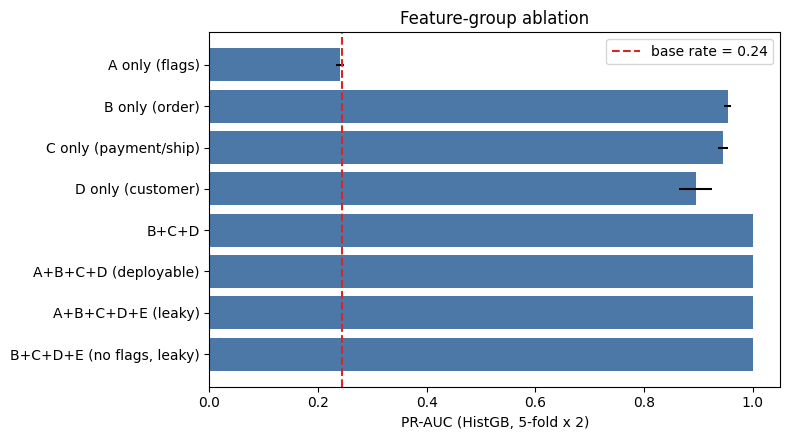

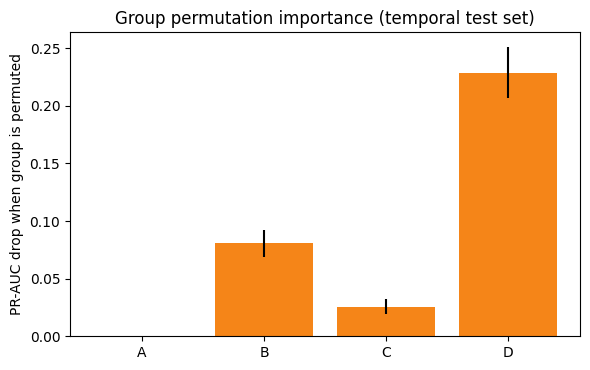

In [3]:
# 3. Run the full pipeline (takes a few minutes)
main(DATA, 'results')

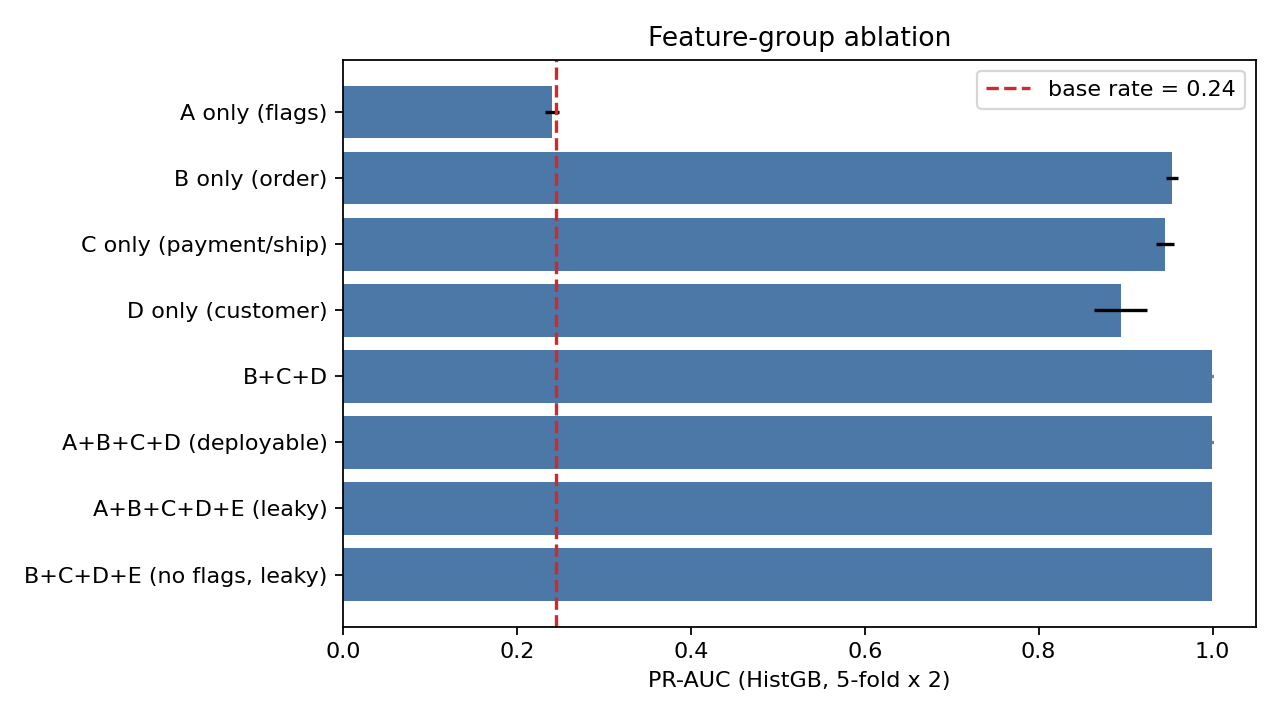

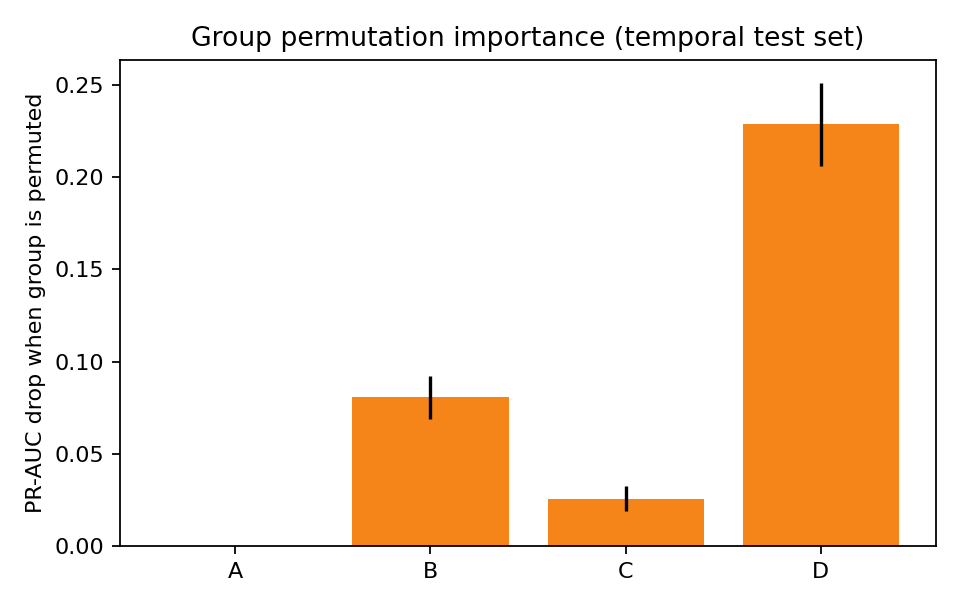

In [4]:
# 4. Figures
from IPython.display import Image, display
display(Image('results/fig_ablation.png'))
display(Image('results/fig_group_importance.png'))

In [5]:
# 5. Result tables
import pandas as pd
for f in ['rule_baselines','flags_added_value_test','temporal_holdout','group_permutation_importance','hard_mode','robustness']:
    print('\n==', f)
    display(pd.read_csv(f'results/{f}.csv').round(3))
abl = pd.read_csv('results/ablation.csv')
display(abl.pivot(index='feature_set', columns='model', values='PR_AUC_mean').round(3))


== rule_baselines


,rule,flagged,precision,recall
0,any_behavioral_flag,1164,0.251,0.398
1,all_three_flags,13,0.231,0.004
2,crypto_wire_or_economy,559,1.000,0.763



== flags_added_value_test


,model,mean_gain_from_flags,wilcoxon_p
0,LogReg,-0.0,1.000
1,Tree(d=4),0.0,1.000
2,RandForest,0.0,0.098
3,HistGB,-0.0,0.078



== temporal_holdout


,feature_set,test_prevalence,PR_AUC,ROC_AUC,F1,MCC,Recall@P95
0,deployable (A-D),0.243,1.0,1.0,0.995,0.994,1.0
1,with leaky E,0.243,1.0,1.0,1.000,1.000,1.0


... (3 outputs left out)

,model,feature_set,PR_AUC_mean,ROC_AUC_mean,F1_mean,MCC_mean,Recall@P95_mean,PR_AUC_sd
0,LogReg,residual features only,0.230,0.467,0.303,-0.044,0.002,0.014
1,LogReg,residual + flags,0.229,0.465,0.296,-0.051,0.003,0.013
2,LogReg,flags only,0.240,0.492,0.240,-0.006,0.000,0.008
3,RandForest,residual features only,0.263,0.525,0.141,0.009,0.002,0.020
4,RandForest,residual + flags,0.266,0.525,0.119,0.013,0.003,0.014
5,RandForest,flags only,0.241,0.494,0.255,0.002,0.000,0.008
6,HistGB,residual features only,0.262,0.527,0.304,0.030,0.003,0.018
7,HistGB,residual + flags,0.259,0.527,0.286,0.015,0.001,0.017
8,HistGB,flags only,0.241,0.493,0.256,0.003,0.000,0.008



== robustness


,test,level,feature_set,lift_over_base,PR_AUC_mean,ROC_AUC_mean,F1_mean,MCC_mean,Recall@P95_mean,PR_AUC_sd
0,prevalence,0.010,A only (flags),1.356,0.014,0.490,0.021,0.004,0.000,0.006
1,prevalence,0.010,A+B+C+D,85.057,0.854,0.997,0.673,0.702,0.700,0.153
2,prevalence,0.010,B+C+D,85.277,0.856,0.997,0.729,0.737,0.700,0.131
3,prevalence,0.050,A only (flags),0.981,0.049,0.480,0.077,-0.012,0.000,0.005
4,prevalence,0.050,A+B+C+D,19.975,0.996,1.000,0.966,0.965,0.967,0.004
5,prevalence,0.050,B+C+D,19.981,0.997,1.000,0.966,0.965,0.967,0.004
6,prevalence,0.100,A only (flags),1.050,0.105,0.509,0.153,0.017,0.000,0.012
7,prevalence,0.100,A+B+C+D,9.978,0.998,1.000,0.974,0.971,1.000,0.001
8,prevalence,0.100,B+C+D,9.980,0.998,1.000,0.974,0.971,1.000,0.001
9,prevalence,0.244,A only (flags),0.996,0.243,0.500,0.270,0.012,0.000,0.009


model,HistGB,LogReg,RandForest,Tree(d=4)
feature_set,,,,
A only (flags),0.241,0.240,0.241,0.241
A+B+C+D (deployable),1.000,0.999,1.000,0.959
A+B+C+D+E (leaky),1.000,0.999,1.000,0.960
B only (order),0.953,0.945,0.947,0.935
B+C+D,1.000,0.999,1.000,0.959
"B+C+D+E (no flags, leaky)",1.000,0.999,1.000,0.959
C only (payment/ship),0.945,0.950,0.936,0.843
D only (customer),0.895,0.883,0.842,0.862


In [6]:
# 6. Download all results
!zip -qr results.zip results
files.download('results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

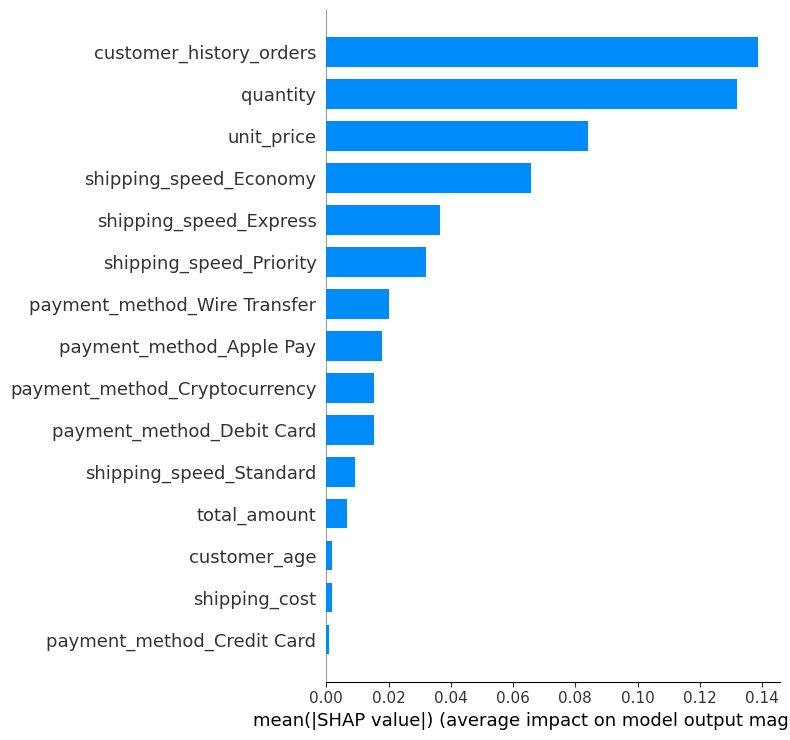

In [7]:
# OPTIONAL: SHAP on a random forest (deployable features A-D). Not required for the main results.
!pip -q install shap
import shap, numpy as np, matplotlib.pyplot as plt
df, X, y = load(DATA)
G = {g: cols(X, n) for g, n in GROUPS.items()}
feats = G["A_behavioral_flags"] + G["B_order_composition"] + G["C_payment_fulfilment"] + G["D_customer_context"]
rf = RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED).fit(X[feats], y)
Xs = X[feats].sample(1000, random_state=SEED)
sv = shap.TreeExplainer(rf).shap_values(Xs)
sv = sv[1] if isinstance(sv, list) else (sv[..., 1] if getattr(sv, "ndim", 2) == 3 else sv)
shap.summary_plot(sv, Xs, plot_type="bar", max_display=15)